# Week 6: Sentiment Analysis and Text Classification

This notebook extends the Week 5 NLP analysis with VADER sentiment
analysis and Decision Tree text classification.

The first step is to verify the available corpus files and Week 5
outputs before preparing the analysis inputs.

## 1. Check the Working Directory and Available Files

Display the current working directory and its contents to locate
the existing corpus and Week 5 outputs. Relative paths will be used
to support reproducibility.

In [1]:
from pathlib import Path

working_dir = Path.cwd()

print("Current working directory:")
print(working_dir)

print("\nAvailable files and folders:")

for item in sorted(working_dir.iterdir()):
    if not item.name.startswith("."):
        item_type = "Folder" if item.is_dir() else "File"
        print(f"{item_type}: {item.name}")

Current working directory:
D:\大王只想要工作\intern\Week 5

Available files and folders:
Folder: data
File: W05_NLP_Pipeline.ipynb
File: W05_Text_Corpus.csv.xlsx
File: W05_Text_Data_Collection.docx
File: W05_Weekly Log.docx
File: W06_Clustering_Analysis.ipynb.ipynb
File: W06_NLP_Technical_Report.docx
File: W06_Sentiment_Classification.ipynb
File: W06_Weekly Log.docx
File: ~$6_Weekly Log.docx


## Load the Week 5 Corpus and Topic Results

Load the exported corpus and LDA document-topic results using
relative paths.

The corpus retains both reviewed text (text_for_nlp) for sentiment
analysis and preprocessed text (text_preprocessed) for TF-IDF modeling.
Document IDs will be used to align the analytical results.

In [2]:
import pandas as pd
from IPython.display import display

# Load the saved Week 5 corpus.
corpus = pd.read_csv(
    "data/W05_Text_Corpus_Preprocessed.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Load the saved document-topic results.
lda_topics = pd.read_csv(
    "data/lda_selected_v1/W05_LDA_Document_Topics.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

print("Corpus documents:", len(corpus))
print("LDA documents:", len(lda_topics))

print("\nCorpus columns:")
print(corpus.columns.tolist())

print("\nLDA columns:")
print(lda_topics.columns.tolist())

display(
    corpus["source_category"]
    .value_counts()
    .rename_axis("source_category")
    .reset_index(name="document_count")
)

display(
    lda_topics[
        ["document_id", "dominant_topic_label"]
    ].head()
)

Corpus documents: 20
LDA documents: 20

Corpus columns:
['document_id', 'source_category', 'source_name', 'source_url', 'final_url', 'title', 'publication_date', 'collection_date', 'collected_at_utc', 'access_method', 'product', 'language', 'text_scope', 'text_raw', 'word_count', 'text_hash', 'html_hash', 'data_origin', 'text_for_nlp', 'prepared_word_count', 'characters_removed', 'review_flag', 'manual_review_status', 'analysis_eligible', 'title_before_review', 'publication_date_extracted', 'title_origin', 'reviewed_cache_hash', 'reviewed_text_hash', 'review_status', 'tokens', 'text_preprocessed', 'token_count_before_filter', 'token_count', 'unique_token_count', 'token_retention_pct']

LDA columns:
['document_id', 'title', 'source_name', 'source_category', 'Topic 1', 'Topic 2', 'Topic 3', 'Topic 4', 'Topic 5', 'dominant_topic', 'dominant_topic_label', 'dominant_topic_proportion']


,source_category,document_count
0,company_content,11
1,press_coverage,6
2,government_program,2
3,editorial_review,1


,document_id,dominant_topic_label
0,DOC_02273cdab72e6af6,Caregiver and Family Support
1,DOC_0df1fe3eec3c36f4,Caregiver and Family Support
2,DOC_0f057b60b2e06fdb,Caregiver and Family Support
3,DOC_18973ef41134ed44,Fari Technical Design
4,DOC_50ffbca5694c8ab5,Caregiver and Family Support


## Validate and Align the Analysis Inputs

Check that document IDs are unique, text fields are non-empty,
and the corpus and LDA results contain the same documents.

Merge topic information using document_id rather than row position
to preserve the correct document-topic relationships.

In [3]:
# Check document identifiers.
for table in [corpus, lda_topics]:
    assert table["document_id"].is_unique, "Duplicate document IDs."
    assert table["document_id"].str.strip().ne("").all(), \
        "Empty document IDs."

# Check both text versions.
for column in ["text_for_nlp", "text_preprocessed"]:
    assert corpus[column].str.strip().ne("").all(), \
        f"Empty text found in {column}."

# Confirm that both files contain the same documents.
assert set(corpus["document_id"]) == set(lda_topics["document_id"]), \
    "The corpus and LDA document IDs do not match."

assert corpus["review_flag"].eq("").all(), \
    "Unresolved corpus review flags."

# Retain topic proportions and dominant-topic information.
topic_columns = [
    column for column in lda_topics.columns
    if column.startswith("Topic ")
]

lda_columns = [
    "document_id",
    *topic_columns,
    "dominant_topic",
    "dominant_topic_label",
    "dominant_topic_proportion",
]

# Join by document ID.
analysis_data = corpus.merge(
    lda_topics[lda_columns],
    on="document_id",
    how="left",
    validate="one_to_one",
)

analysis_data = (
    analysis_data
    .sort_values("document_id")
    .reset_index(drop=True)
)

assert len(analysis_data) == len(corpus), \
    "The document count changed during merging."

print("Input validation and merging passed.")
print("Documents ready for Week 6:", len(analysis_data))

display(
    analysis_data["dominant_topic_label"]
    .value_counts()
    .rename_axis("dominant_topic_label")
    .reset_index(name="document_count")
)

Input validation and merging passed.
Documents ready for Week 6: 20


,dominant_topic_label,document_count
0,Caregiver and Family Support,12
1,Social Companionship,3
2,Robotic Pets and Wellbeing,2
3,Product Features and Use,2
4,Fari Technical Design,1


## Inspect the Two Text Versions

Preview one document from each source category to check the reviewed
text and preprocessed text.

The reviewed text (text_for_nlp) will be used for VADER sentiment
analysis. The preprocessed text (text_preprocessed) will be used for
TF-IDF modeling. Excerpts are displayed for inspection only; the
analysis will use the full document text.

In [4]:
# Preview one document from each source category.
for category, group in analysis_data.groupby("source_category"):
    document = group.iloc[0]

    print(f"\n===== {category} =====")
    print("Document ID:", document["document_id"])
    print("Title:", document["title"])
    print("Topic:", document["dominant_topic_label"])

    print("\nReviewed text preview:")
    print(
        document["text_for_nlp"][:500]
        .replace("\n", " ")
    )

    print("\nPreprocessed text preview:")
    print(document["text_preprocessed"][:300])


===== company_content =====
Document ID: DOC_02273cdab72e6af6
Title: The Emotional Toll of Caregiving and How to Prevent Burnout
Topic: Caregiver and Family Support

Reviewed text preview:
Caring for an aging parent or loved one can be one of the most meaningful roles a person takes on. It brings moments of connection, gratitude, and purpose. At the same time, caregiving can also bring emotional exhaustion, stress, and a sense of being stretched too thin. Many caregivers find themselves balancing full-time jobs, family responsibilities, and financial pressures while also trying to give consistent attention to the senior in their lives. Over time, this can lead to caregiver burnout

Preprocessed text preview:
care aging parent love one one meaningful role person take bring moment connection gratitude time caregiving also bring emotional exhaustion stress sense stretch many caregiver find balance full time job family responsibility financial pressure also try give consistent attention s

## Save the Week 6 Analysis Input

Export the validated corpus with its LDA topic information to a
separate Week 6 input file.

Reload the exported file to verify that document IDs, both text
versions, and topic labels are preserved. Existing Week 5 files
remain the source inputs.

In [5]:
from pathlib import Path

# Create a folder for the prepared Week 6 input.
output_dir = Path("data") / "week6_inputs"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "W06_Analysis_Input.csv"

# Save the full documents and topic information.
analysis_data.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g",
)

# Reload and verify the key fields.
saved_data = pd.read_csv(
    output_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

check_columns = [
    "document_id",
    "text_for_nlp",
    "text_preprocessed",
    "dominant_topic_label",
]

assert len(saved_data) == len(analysis_data), \
    "The document count changed after saving."

assert saved_data[check_columns].equals(
    analysis_data[check_columns]
), "Document IDs, text, or topic labels changed after saving."

print("Export and reload validation passed.")
print("Saved:", output_path.as_posix())
print("Documents:", len(saved_data))

Export and reload validation passed.
Saved: data/week6_inputs/W06_Analysis_Input.csv
Documents: 20


## Initialize VADER Sentiment Analysis

Use NLTK's VADER sentiment analyzer to score the full reviewed text
in text_for_nlp. This text preserves sentence structure, negation,
punctuation, and capitalization.

Load the VADER lexicon from the local NLTK resource cache.
Download it automatically if it is not already available.

In [6]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Load the analyzer, downloading its lexicon only if needed.
try:
    sentiment_analyzer = SentimentIntensityAnalyzer()

except LookupError:
    nltk.download(
        "vader_lexicon",
        raise_on_error=True,
    )
    sentiment_analyzer = SentimentIntensityAnalyzer()

print("VADER initialized successfully.")
print("Documents ready for sentiment analysis:", len(analysis_data))

VADER initialized successfully.
Documents ready for sentiment analysis: 20


## Calculate Document-Level Sentiment Scores

Apply VADER to the full reviewed text of each document and retain
its negative, neutral, positive, and compound scores.

Assign sentiment categories using the compound score:
- Positive: compound >= 0.05
- Negative: compound <= -0.05
- Neutral: -0.05 < compound < 0.05

The compound score measures sentiment polarity, not prediction
confidence or the probability that a document is positive.

In [7]:
# Calculate all four VADER scores for each full document.
vader_scores = (
    analysis_data["text_for_nlp"]
    .map(sentiment_analyzer.polarity_scores)
    .apply(pd.Series)
)

# Preserve the corpus and attach sentiment scores.
sentiment_results = analysis_data.copy()

for score in ["neg", "neu", "pos", "compound"]:
    sentiment_results[f"vader_{score}"] = vader_scores[score]


# Convert the compound score into a sentiment category.
def assign_sentiment(compound):
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    return "Neutral"


sentiment_results["sentiment_label"] = (
    sentiment_results["vader_compound"]
    .map(assign_sentiment)
)

assert sentiment_results["vader_compound"].between(-1, 1).all(), \
    "Compound scores must be between -1 and 1."

print("Documents scored:", len(sentiment_results))

display(
    sentiment_results[
        [
            "title",
            "source_category",
            "vader_compound",
            "sentiment_label",
        ]
    ].sort_values("vader_compound")
)

print("\nSentiment category counts:")
print(sentiment_results["sentiment_label"].value_counts())

Documents scored: 20


,title,source_category,vader_compound,sentiment_label
10,How AI companion robots are helping seniors fe...,press_coverage,-0.6316,Negative
17,NYSOFA introduces ElliQ to older adults in New...,government_program,0.9972,Positive
13,"ElliQ, A Social Home Robot for Older Adults, N...",press_coverage,0.9984,Positive
12,NYSOFA reports ElliQ pilot outcomes and partne...,government_program,0.9986,Positive
16,ElliQ Review: a Robot Companion for Seniors │ ...,editorial_review,0.9986,Positive
3,Fari,company_content,0.9987,Positive
9,‘Care bots’ are on the rise and replacing huma...,press_coverage,0.9991,Positive
2,Your Parent Won’t Ask for Help. Here’s How to ...,company_content,0.9992,Positive
15,How Technology Is Changing Caregiving at Home,company_content,0.9993,Positive
7,10 Activities You Can Do with ElliQ This Month,company_content,0.9994,Positive



Sentiment category counts:
sentiment_label
Positive    19
Negative     1
Name: count, dtype: int64


## Visualize the Overall Sentiment Distribution

Plot the document-level compound scores across the full -1 to +1
range. Mark the standard negative and positive thresholds.

The distribution describes VADER scores for this collected corpus.
Scores concentrated near +1 require further inspection and should
not be interpreted as customer satisfaction or model confidence.

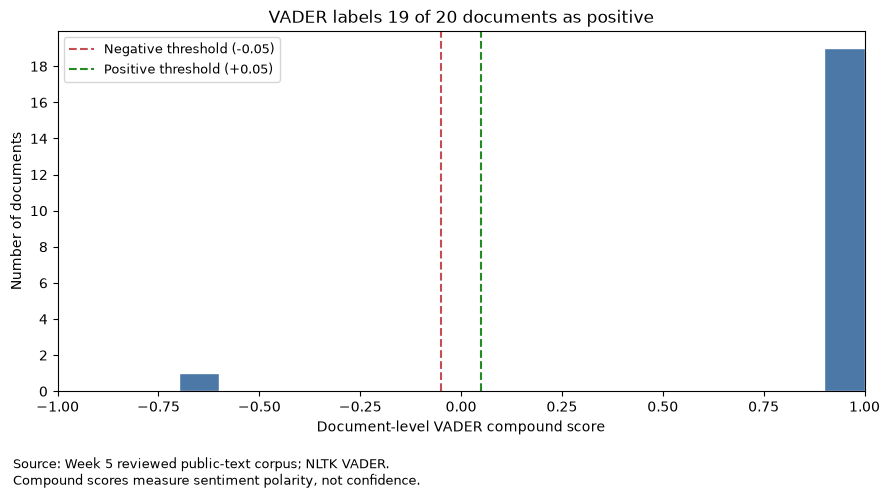

Saved: data/week6_sentiment/figures/W06_VADER_Compound_Distribution.png


In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Calculate counts for the finding-statement title.
positive_count = sentiment_results["sentiment_label"].eq("Positive").sum()
document_count = len(sentiment_results)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    sentiment_results["vader_compound"],
    bins=20,
    range=(-1, 1),
    color="#4C78A8",
    edgecolor="white",
)

ax.axvline(
    -0.05,
    color="#C44E52",
    linestyle="--",
    label="Negative threshold (-0.05)",
)

ax.axvline(
    0.05,
    color="#228B22",
    linestyle="--",
    label="Positive threshold (+0.05)",
)

ax.set_title(
    f"VADER labels {positive_count} of {document_count} documents as positive"
)
ax.set_xlabel("Document-level VADER compound score")
ax.set_ylabel("Number of documents")
ax.set_xlim(-1, 1)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(fontsize=9)

fig.text(
    0.02,
    0.02,
    "Source: Week 5 reviewed public-text corpus; NLTK VADER.\n"
    "Compound scores measure sentiment polarity, not confidence.",
    fontsize=9,
)

fig.tight_layout(rect=(0, 0.09, 1, 1))

# Save the chart using a relative path.
figure_dir = Path("data") / "week6_sentiment" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "W06_VADER_Compound_Distribution.png"

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print("Saved:", figure_path.as_posix())

## Compare Sentiment by Source Category

Summarize document counts, mean and median compound scores, score
ranges, and sentiment-category counts for each source category.

Each document receives equal weight within its group. Group sizes
are reported because the categories are uneven, and the editorial
review category contains only one document.

In [9]:
# Summarize compound scores within each source category.
source_summary = sentiment_results.groupby("source_category").agg(
    document_count=("document_id", "size"),
    mean_compound=("vader_compound", "mean"),
    median_compound=("vader_compound", "median"),
    min_compound=("vader_compound", "min"),
    max_compound=("vader_compound", "max"),
)

# Count positive, neutral, and negative documents.
source_sentiment_counts = pd.crosstab(
    sentiment_results["source_category"],
    sentiment_results["sentiment_label"],
).reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0,
)

source_summary = source_summary.join(source_sentiment_counts)

source_summary["positive_pct"] = (
    source_summary["Positive"]
    / source_summary["document_count"]
    * 100
)

source_summary = source_summary.reset_index()

# Round only the displayed table; retain full precision in the data.
display(source_summary.round(4))

,source_category,document_count,mean_compound,median_compound,min_compound,max_compound,Positive,Neutral,Negative,positive_pct
0,company_content,11,0.9995,0.9996,0.9987,0.9999,11,0,0,100.0000
1,editorial_review,1,0.9986,0.9986,0.9986,0.9986,1,0,0,100.0000
2,government_program,2,0.9979,0.9979,0.9972,0.9986,2,0,0,100.0000
3,press_coverage,6,0.7275,0.9994,-0.6316,0.9998,5,0,1,83.3333


## Visualize Sentiment by Source Category

Display individual document scores alongside each source category's
mean compound score. Include document counts in the category labels.

The plot shows how the single negative press document affects its
group mean. Small differences among scores near +1 should be
interpreted cautiously, especially for categories with few documents.

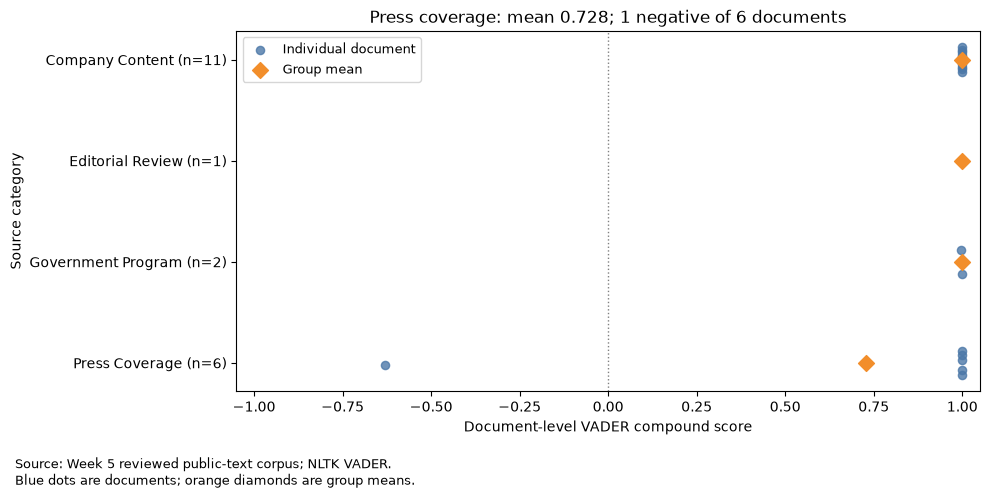

Saved: data/week6_sentiment/figures/W06_VADER_Sentiment_By_Source.png


In [10]:
import numpy as np

# Arrange categories by their mean compound score.
plot_summary = (
    source_summary
    .sort_values("mean_compound")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 5))

# Plot every document with small, deterministic vertical offsets.
for position, row in plot_summary.iterrows():
    group = sentiment_results.loc[
        sentiment_results["source_category"].eq(row["source_category"])
    ]

    offsets = (
        np.linspace(-0.12, 0.12, len(group))
        if len(group) > 1 else np.zeros(1)
    )

    ax.scatter(
        group["vader_compound"],
        position + offsets,
        color="#4C78A8",
        s=35,
        alpha=0.8,
        label="Individual document" if position == 0 else None,
    )

# Overlay group means.
ax.scatter(
    plot_summary["mean_compound"],
    range(len(plot_summary)),
    color="#F28E2B",
    marker="D",
    s=65,
    label="Group mean",
    zorder=3,
)

category_labels = [
    f"{row.source_category.replace('_', ' ').title()} "
    f"(n={row.document_count})"
    for row in plot_summary.itertuples(index=False)
]

press = source_summary.loc[
    source_summary["source_category"].eq("press_coverage")
].iloc[0]

ax.set_yticks(range(len(plot_summary)), labels=category_labels)
ax.set_xlim(-1.05, 1.05)
ax.axvline(0, color="gray", linestyle=":", linewidth=1)

ax.set_title(
    f"Press coverage: mean {press['mean_compound']:.3f}; "
    f"{int(press['Negative'])} negative of "
    f"{int(press['document_count'])} documents"
)
ax.set_xlabel("Document-level VADER compound score")
ax.set_ylabel("Source category")
ax.legend(loc="upper left", fontsize=9)

fig.text(
    0.02, 0.02,
    "Source: Week 5 reviewed public-text corpus; NLTK VADER.\n"
    "Blue dots are documents; orange diamonds are group means.",
    fontsize=9,
)

fig.tight_layout(rect=(0, 0.09, 1, 1))

figure_path = figure_dir / "W06_VADER_Sentiment_By_Source.png"
fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print("Saved:", figure_path.as_posix())

## Compare Sentiment by Dominant LDA Topic

Group documents by their highest-proportion LDA topic and summarize
their compound scores and sentiment categories.

These are full-document sentiment scores grouped by dominant topic,
rather than sentiment scores for individual topic-specific passages.
Report group sizes because some topics contain only one or two
documents.

In [11]:
# Summarize document-level sentiment by dominant topic.
topic_summary = sentiment_results.groupby("dominant_topic_label").agg(
    document_count=("document_id", "size"),
    mean_compound=("vader_compound", "mean"),
    median_compound=("vader_compound", "median"),
    min_compound=("vader_compound", "min"),
    max_compound=("vader_compound", "max"),
)

# Count sentiment categories within each topic.
topic_sentiment_counts = pd.crosstab(
    sentiment_results["dominant_topic_label"],
    sentiment_results["sentiment_label"],
).reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0,
)

topic_summary = topic_summary.join(topic_sentiment_counts)

topic_summary["positive_pct"] = (
    topic_summary["Positive"]
    / topic_summary["document_count"]
    * 100
)

topic_summary = (
    topic_summary
    .reset_index()
    .sort_values("mean_compound")
    .reset_index(drop=True)
)

display(topic_summary.round(4))

,dominant_topic_label,document_count,mean_compound,median_compound,min_compound,max_compound,Positive,Neutral,Negative,positive_pct
0,Product Features and Use,2,0.1835,0.1835,-0.6316,0.9986,1,0,1,50.0
1,Fari Technical Design,1,0.9987,0.9987,0.9987,0.9987,1,0,0,100.0
2,Caregiver and Family Support,12,0.9992,0.9994,0.9972,0.9999,12,0,0,100.0
3,Social Companionship,3,0.9993,0.9996,0.9984,0.9998,3,0,0,100.0
4,Robotic Pets and Wellbeing,2,0.9997,0.9997,0.9997,0.9997,2,0,0,100.0


## Visualize Sentiment by Dominant Topic

Plot individual document scores and group means for each dominant
LDA topic, with document counts shown in the labels.

Product Features and Use contains one positive and one negative
document. Its mean therefore summarizes opposing scores rather
than a consistent sentiment across documents.

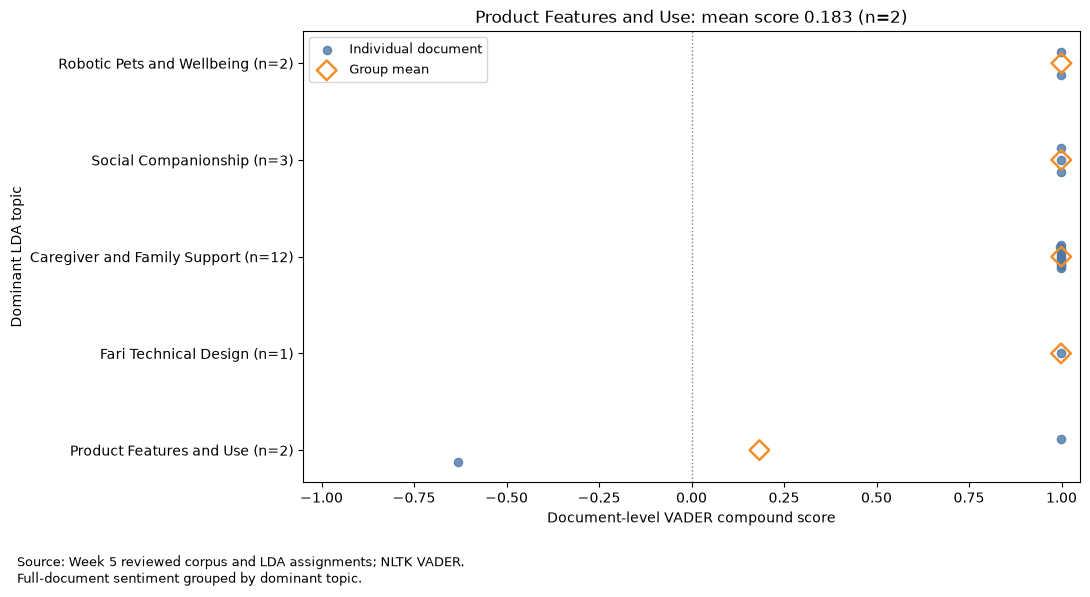

Saved: data/week6_sentiment/figures/W06_VADER_Sentiment_By_Topic.png


In [12]:
topic_plot = topic_summary.copy()

fig, ax = plt.subplots(figsize=(11, 6))

# Plot individual document scores.
for position, row in topic_plot.iterrows():
    group = sentiment_results.loc[
        sentiment_results["dominant_topic_label"].eq(
            row["dominant_topic_label"]
        )
    ]

    offsets = (
        np.linspace(-0.12, 0.12, len(group))
        if len(group) > 1 else np.zeros(1)
    )

    ax.scatter(
        group["vader_compound"],
        position + offsets,
        color="#4C78A8",
        s=35,
        alpha=0.8,
        label="Individual document" if position == 0 else None,
    )

# Hollow diamonds keep individual points visible beneath the means.
ax.scatter(
    topic_plot["mean_compound"],
    range(len(topic_plot)),
    marker="D",
    facecolors="none",
    edgecolors="#F28E2B",
    linewidths=1.8,
    s=100,
    label="Group mean",
    zorder=3,
)

topic_labels = [
    f"{row.dominant_topic_label} (n={row.document_count})"
    for row in topic_plot.itertuples(index=False)
]

lowest_topic = topic_plot.iloc[0]

ax.set_yticks(range(len(topic_plot)), labels=topic_labels)
ax.set_xlim(-1.05, 1.05)
ax.axvline(0, color="gray", linestyle=":", linewidth=1)

ax.set_title(
    f"{lowest_topic['dominant_topic_label']}: "
    f"mean score {lowest_topic['mean_compound']:.3f} "
    f"(n={int(lowest_topic['document_count'])})"
)
ax.set_xlabel("Document-level VADER compound score")
ax.set_ylabel("Dominant LDA topic")
ax.legend(loc="upper left", fontsize=9)

fig.text(
    0.02, 0.02,
    "Source: Week 5 reviewed corpus and LDA assignments; NLTK VADER.\n"
    "Full-document sentiment grouped by dominant topic.",
    fontsize=9,
)

fig.tight_layout(rect=(0, 0.09, 1, 1))

figure_path = figure_dir / "W06_VADER_Sentiment_By_Topic.png"
fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print("Saved:", figure_path.as_posix())

## Inspect Potential Sentiment Scoring Errors

Inspect the lowest-scoring document and the editorial product review
using their full reviewed text.

Check whether sentiment concerns the product itself, background
problems, or a mixture of praise and criticism. This targeted review
documents illustrative limitations; it does not estimate sentiment
accuracy or replace the later 20-document classification-label audit.

In [13]:
# Select the lowest-scoring document and the editorial review.
review_documents = pd.concat(
    [
        sentiment_results.nsmallest(1, "vader_compound"),
        sentiment_results.loc[
            sentiment_results["source_name"].eq("The Senior List")
        ],
    ],
    ignore_index=True,
).drop_duplicates("document_id")

# Display the full text for contextual inspection.
for _, document in review_documents.iterrows():
    print("\n" + "=" * 70)
    print("Document ID:", document["document_id"])
    print("Title:", document["title"])
    print("Publisher:", document["source_name"])
    print("Source URL:", document["source_url"])
    print("Compound score:", document["vader_compound"])
    print("VADER label:", document["sentiment_label"])

    print("\nFull reviewed text:")
    print(document["text_for_nlp"])


Document ID: DOC_9a84489b2a82091f
Title: How AI companion robots are helping seniors feel less lonely
Publisher: WHYY
Source URL: https://whyy.org/segments/how-ai-companion-robots-are-helping-seniors-feel-less-lonely/
Compound score: -0.6316
VADER label: Negative

Full reviewed text:
When 86-year-old Anthony Niemiec’s wife passed away, he found himself isolated and struggled to fill his days with activity.
“I was married 57 years, and I always had action. And she was very active. And all of a sudden, being alone, it’s difficult,” Niemiec said. He fondly recalls busier days, whether it was he and his wife decorating their home or his many days spent at sea with the U.S. Navy.
After his wife died, a new companion recently moved into his home in Beacon, New York. She’s chatty, 8.5 inches tall and goes by the name of ElliQ.
Niemiec introduces me to ElliQ, a small, lamp-looking device sitting on his wooden dinner table.
“It’s an honor to have you with us today,” ElliQ says in a monosyllabi

### Targeted Sentiment Review: Findings and Limitations

The two inspected documents show that full-document sentiment
does not necessarily reflect the author's evaluation of the product.

#### Case 1: Negative Context in a Broadly Favorable Product Story

- Document ID: DOC_9a84489b2a82091f
- Publisher: WHYY
- VADER compound: -0.6316 (Negative)

The article discusses bereavement, isolation, and loneliness alongside
a user's favorable experience with ElliQ. It also acknowledges privacy
and dependence concerns.

The negative document score does not adequately represent the broadly
favorable account of the product's companionship role. This illustrates
a distinction between sentiment about background circumstances and
sentiment directed toward the product.

#### Case 2: Positive Overall Score Despite a Critical Verdict

- Document ID: DOC_dfba7aa407b222fa
- Publisher: The Senior List
- VADER compound: 0.9986 (Positive)

The review recognizes useful features but criticizes subscription
costs, limited conversations, delayed video calls, system freezes,
and the lack of emergency-response functionality. Its final verdict
questions the product's usefulness.

The near-maximum positive score masks these criticisms and should
not be interpreted as strong product endorsement.

#### Implications for Interpretation

The original VADER scores are retained for reproducibility.
Group comparisons describe document-level language polarity rather
than customer satisfaction or product-specific sentiment.

These two deliberately selected cases illustrate limitations.
They do not establish a corpus-wide error rate or demonstrate how
frequently each issue occurs. Product-specific or passage-level
analysis would be a useful future extension.

## Export and Verify the Sentiment Results

Save document-level scores, source-category summaries, and
dominant-topic summaries using relative paths.

Export the original numerical values without display rounding.
Reload the document scores to verify that document IDs, sentiment
labels, and all four VADER scores are preserved.

In [14]:
# Prepare a compact document-level results table.
score_columns = [
    "vader_neg",
    "vader_neu",
    "vader_pos",
    "vader_compound",
]

document_scores = sentiment_results[
    [
        "document_id",
        "title",
        "source_name",
        "source_category",
        "source_url",
        "dominant_topic",
        "dominant_topic_label",
        *score_columns,
        "sentiment_label",
    ]
].copy()

# Save all three result tables.
sentiment_dir = Path("data") / "week6_sentiment"
sentiment_dir.mkdir(parents=True, exist_ok=True)

export_tables = {
    "W06_VADER_Document_Scores.csv": document_scores,
    "W06_VADER_Source_Summary.csv": source_summary,
    "W06_VADER_Topic_Summary.csv": topic_summary,
}

for filename, table in export_tables.items():
    output_path = sentiment_dir / filename

    table.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g",
    )

    print("Saved:", output_path.as_posix())

# Reload document scores and verify their contents.
saved_scores = pd.read_csv(
    sentiment_dir / "W06_VADER_Document_Scores.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

assert saved_scores["document_id"].tolist() == \
    document_scores["document_id"].tolist(), "Document IDs changed."

assert saved_scores["sentiment_label"].tolist() == \
    document_scores["sentiment_label"].tolist(), "Sentiment labels changed."

assert np.allclose(
    saved_scores[score_columns].to_numpy(),
    document_scores[score_columns].to_numpy(),
    rtol=0,
    atol=1e-12,
), "VADER scores changed after saving."

print("\nSentiment export and reload validation passed.")

Saved: data/week6_sentiment/W06_VADER_Document_Scores.csv
Saved: data/week6_sentiment/W06_VADER_Source_Summary.csv
Saved: data/week6_sentiment/W06_VADER_Topic_Summary.csv

Sentiment export and reload validation passed.


## Save the Sentiment Analysis Configuration

Record the input files, text field, sentiment thresholds, topic
grouping method, software versions, and VADER lexicon fingerprint.

File hashes identify the inputs and exported results associated
with this run. The targeted review is recorded as a qualitative
diagnostic, not an accuracy evaluation.

In [15]:
import hashlib
import json
import sys

from importlib.metadata import version

# Record the source inputs and prepared dataset.
input_paths = [
    Path("data/W05_Text_Corpus_Preprocessed.csv"),
    Path("data/lda_selected_v1/W05_LDA_Document_Topics.csv"),
    Path("data/week6_inputs/W06_Analysis_Input.csv"),
]

sentiment_config = {
    "method": "NLTK VADER",
    "analysis_unit": "Full reviewed document",
    "text_column": "text_for_nlp",
    "positive_rule": "compound >= 0.05",
    "negative_rule": "compound <= -0.05",
    "neutral_rule": "-0.05 < compound < 0.05",
    "topic_grouping": "Highest-proportion Week 5 LDA topic",
    "document_count": len(sentiment_results),
    "sentiment_counts": {
        label: int(count)
        for label, count in
        sentiment_results["sentiment_label"].value_counts().items()
    },
    "input_sha256": {
        path.as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
        for path in input_paths
    },
    "lexicon_sha256": hashlib.sha256(
        sentiment_analyzer.lexicon_file.encode("utf-8")
    ).hexdigest(),
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in ["nltk", "pandas", "numpy", "matplotlib"]
    },
    "targeted_review_document_ids": (
        review_documents["document_id"].tolist()
    ),
    "review_scope": (
        "Two deliberately selected cases; qualitative diagnostics "
        "only, with no corpus-wide accuracy estimate."
    ),
    "output_sha256": {
        filename: hashlib.sha256(
            (sentiment_dir / filename).read_bytes()
        ).hexdigest()
        for filename in export_tables
    },
}

config_path = sentiment_dir / "W06_VADER_Config.json"

config_path.write_text(
    json.dumps(sentiment_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Verify that the saved configuration reloads correctly.
saved_config = json.loads(config_path.read_text(encoding="utf-8"))
assert saved_config == sentiment_config, "Configuration reload mismatch."

print("Sentiment configuration saved and verified.")
print("Saved:", config_path.as_posix())

Sentiment configuration saved and verified.
Saved: data/week6_sentiment/W06_VADER_Config.json


## Define the Functional Classification Categories

Classify documents according to their main content function:

1. Product Performance Feedback:
   Discussion or evaluation of features, usability, reliability,
   and product limitations.

2. Market Adoption Signal:
   Evidence or discussion of pilots, deployment, partnerships,
   purchasing, and adoption.

3. Competitive Positioning:
   Comparisons with competing products, alternatives, or competing
   approaches to care.

4. Regulatory or Safety Concern:
   Discussion of privacy, consent, regulation, liability, or safety risks.

Use one primary label per document. The keyword rules will record
overlapping matches and unmatched documents for inspection.

Category definitions guide both rule design and the later manual
audit. Company descriptions remain company claims rather than
independently verified performance evidence.

In [16]:
import pandas as pd
from IPython.display import display

RANDOM_STATE = 42

# Load the prepared input using a relative path.
classification_data = pd.read_csv(
    "data/week6_inputs/W06_Analysis_Input.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Validate the fields needed for labeling and modeling.
required_columns = {
    "document_id",
    "title",
    "source_name",
    "text_for_nlp",
    "text_preprocessed",
}

assert required_columns.issubset(classification_data.columns), \
    "Required classification columns are missing."

assert not classification_data.empty, "The corpus is empty."
assert classification_data["document_id"].is_unique, \
    "Duplicate document IDs."

for column in ["text_for_nlp", "text_preprocessed"]:
    assert classification_data[column].str.strip().ne("").all(), \
        f"Empty text in {column}."

# Keep a consistent document order.
classification_data = (
    classification_data
    .sort_values("document_id")
    .reset_index(drop=True)
)

print("Classification input loaded successfully.")
print("Documents:", len(classification_data))

Classification input loaded successfully.
Documents: 20


## Generate Initial Keyword-Based Labels

Apply predefined keywords to the reviewed document text using
case-insensitive, whole-word or whole-phrase matching.

Each keyword contributes at most one point per document. Assign
the category with the highest score. Mark tied results as Ambiguous
and documents with no matches as Unmatched.

These provisional labels indicate keyword evidence, which may
differ from the document's primary content function. Retain matched
keywords and category scores to support inspection.

In [17]:
import json
import re

KEYWORD_RULES = {
    "Product Performance Feedback": [
        "review", "testing", "performance", "reliability",
        "usability", "features", "bugs", "freeze", "delay",
    ],
    "Market Adoption Signal": [
        "adoption", "deployment", "pilot", "partnership",
        "rollout", "launch", "purchase", "subscription",
    ],
    "Competitive Positioning": [
        "competitor", "competition", "alternative", "alternatives",
        "compared with", "compared to", "versus",
        "alexa", "google assistant",
    ],
    "Regulatory or Safety Concern": [
        "privacy", "consent", "regulation", "regulatory",
        "liability", "data protection", "safety concerns",
        "safety risks", "emergency response",
    ],
}


def assign_functional_label(text):
    # Normalize case and whitespace while preserving word content.
    normalized_text = " ".join(text.casefold().split())

    matches = {
        category: [
            keyword for keyword in keywords
            if re.search(
                r"\b" + re.escape(keyword) + r"\b",
                normalized_text,
            )
        ]
        for category, keywords in KEYWORD_RULES.items()
    }

    scores = {
        category: len(keywords)
        for category, keywords in matches.items()
    }

    highest_score = max(scores.values())

    winners = [
        category for category, score in scores.items()
        if score == highest_score
    ]

    if highest_score == 0:
        label = "Unmatched"
    elif len(winners) > 1:
        label = "Ambiguous"
    else:
        label = winners[0]

    return {
        "rule_label": label,
        "highest_keyword_score": highest_score,
        "category_scores": json.dumps(scores),
        "matched_keywords": json.dumps(matches),
    }


# Create a separate table without changing the source corpus.
rule_results = (
    classification_data["text_for_nlp"]
    .map(assign_functional_label)
    .apply(pd.Series)
)

labeled_data = classification_data.join(rule_results)

print("Initial keyword-label distribution:")
display(
    labeled_data["rule_label"]
    .value_counts()
    .rename_axis("rule_label")
    .reset_index(name="document_count")
)

display(
    labeled_data[
        ["document_id", "title", "rule_label", "highest_keyword_score"]
    ]
)

Initial keyword-label distribution:


,rule_label,document_count
0,Ambiguous,6
1,Product Performance Feedback,5
2,Competitive Positioning,3
3,Unmatched,2
4,Regulatory or Safety Concern,2
5,Market Adoption Signal,2


,document_id,title,rule_label,highest_keyword_score
0,DOC_02273cdab72e6af6,The Emotional Toll of Caregiving and How to Pr...,Competitive Positioning,1
1,DOC_0df1fe3eec3c36f4,"How to Choose Between Home Care, Assisted Livi...",Ambiguous,1
2,DOC_0f057b60b2e06fdb,Your Parent Won’t Ask for Help. Here’s How to ...,Unmatched,0
3,DOC_18973ef41134ed44,Fari,Product Performance Feedback,3
4,DOC_50ffbca5694c8ab5,How to Help an Aging Parent Stay Socially Conn...,Competitive Positioning,1
5,DOC_5da508bf5e967d1d,The Future of Aging: Why Connection Matters Mo...,Product Performance Feedback,1
6,DOC_601dcb0a9e7cfc80,‘Care bots’: a dream for carers or a dangerous...,Competitive Positioning,1
7,DOC_76ed7a86d9237deb,10 Activities You Can Do with ElliQ This Month,Regulatory or Safety Concern,1
8,DOC_775ed64b8f6204c2,What Yale Researchers Discovered About How You...,Product Performance Feedback,1
9,DOC_780610e1f4509b20,‘Care bots’ are on the rise and replacing huma...,Ambiguous,1


## Prepare the Manual Label Audit

Retain the initial keyword rules and their outputs as a baseline.

Review all 20 documents in a reproducibly randomized order.
The manual audit table excludes automated labels and keyword matches
to reduce their influence on the review.

Assign the category that best represents the document's main content
function and record a brief rationale. Use Other / Unclear when none
of the four categories adequately describes the document.

Report rule coverage separately from errors among assigned labels.
Ambiguous and Unmatched are abstentions, not functional categories.

In [18]:
from pathlib import Path

classification_dir = Path("data") / "week6_classification"
classification_dir.mkdir(parents=True, exist_ok=True)

# Preserve the current rule definitions.
rules_path = classification_dir / "W06_Keyword_Rules_v1.json"

if rules_path.exists():
    saved_rules = json.loads(rules_path.read_text(encoding="utf-8"))
    assert saved_rules == KEYWORD_RULES, \
        "The v1 rules have changed. Use a new version before saving."
else:
    rules_path.write_text(
        json.dumps(KEYWORD_RULES, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

# Save the initial automated labels and their supporting evidence.
baseline_columns = [
    "document_id",
    "title",
    "rule_label",
    "highest_keyword_score",
    "category_scores",
    "matched_keywords",
]

labeled_data[baseline_columns].to_csv(
    classification_dir / "W06_Rule_Labels_v1.csv",
    index=False,
    encoding="utf-8-sig",
)

# Prepare the manual review without displaying automated labels.
audit_template = (
    classification_data
    .sample(n=20, random_state=RANDOM_STATE)
    [
        [
            "document_id",
            "title",
            "source_name",
            "text_for_nlp",
        ]
    ]
    .reset_index(drop=True)
)

audit_template["manual_label"] = ""
audit_template["manual_rationale"] = ""

audit_path = classification_dir / "W06_Manual_Label_Audit.csv"

# Preserve manual entries when the notebook is rerun.
if audit_path.exists():
    print("Existing manual audit retained:", audit_path.as_posix())
else:
    audit_template.to_csv(
        audit_path,
        index=False,
        encoding="utf-8-sig",
    )
    print("Manual audit created:", audit_path.as_posix())

print("Baseline rules and labels saved.")
print("Documents selected for manual review:", len(audit_template))

Existing manual audit retained: data/week6_classification/W06_Manual_Label_Audit.csv
Baseline rules and labels saved.
Documents selected for manual review: 20


## Review Documents Manually

Display the first document without a completed manual label.
Read its full text and select the category that best describes
its main content function.

Record a brief rationale based on the article's central purpose.
Use Other / Unclear when none of the four categories fits adequately.
Automated labels are omitted from this review display.

In [19]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [20]:
# Record the human-reviewed judgment for this specific document.
review_id = "DOC_02273cdab72e6af6"

manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Fill only an empty record; preserve existing manual decisions.
existing_label = manual_audit.loc[
    document_mask, "manual_label"
].iloc[0]

if existing_label.strip() == "":
    manual_audit.loc[document_mask, "manual_label"] = "Other / Unclear"

    manual_audit.loc[document_mask, "manual_rationale"] = (
        "Primarily explains caregiver burnout and coping strategies, "
        "with ElliQ promoted as a supporting tool. The main purpose "
        "is caregiver education and product promotion."
    )

    manual_audit.to_csv(
        audit_path,
        index=False,
        encoding="utf-8-sig",
    )

    print("Manual review saved:", review_id)
else:
    print("Existing manual review retained:", review_id)

print(
    "Documents reviewed:",
    manual_audit["manual_label"].str.strip().ne("").sum(),
)

Existing manual review retained: DOC_02273cdab72e6af6
Documents reviewed: 20


In [21]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [22]:
# Record the human-reviewed judgment for this specific document.
review_id = "DOC_ec7ad2898ff92252"

manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Fill only an empty record; preserve existing manual decisions.
existing_label = manual_audit.loc[
    document_mask, "manual_label"
].iloc[0]

if existing_label.strip() == "":
    manual_audit.loc[document_mask, "manual_label"] = "Market Adoption Signal"

    manual_audit.loc[document_mask, "manual_rationale"] = (
    "Announces NYSOFA's rollout of ElliQ to over 800 older adults "
    "and its partnership with Intuition Robotics. The main purpose "
    "is to report a concrete deployment and adoption initiative."
    )

    manual_audit.to_csv(
        audit_path,
        index=False,
        encoding="utf-8-sig",
    )

    print("Manual review saved:", review_id)
else:
    print("Existing manual review retained:", review_id)

print(
    "Documents reviewed:",
    manual_audit["manual_label"].str.strip().ne("").sum(),
)

Existing manual review retained: DOC_ec7ad2898ff92252
Documents reviewed: 20


In [23]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [24]:
# ===== Change only these three variables for each document =====

review_id = "DOC_d78d4551e520e99a"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily describes the functions and claimed caregiving benefits "
    "of home-care technologies and ElliQ. Classified under the codebook's "
    "inclusion of product-feature discussions. These are promotional "
    "company claims rather than independently evaluated performance."
)


# ===== Save the review =====

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_d78d4551e520e99a
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [25]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [26]:
# ===== Change only these three variables for each document =====

review_id = "DOC_0df1fe3eec3c36f4"

manual_label = "Competitive Positioning"

manual_rationale = (
    "Compares home care, assisted living, and technology-based "
    "companionship through their benefits and limitations. Positions "
    "ElliQ as complementary support for aging at home. Comparison "
    "between alternative care approaches is the article's central purpose."
)


# ===== Save the review =====

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_0df1fe3eec3c36f4
Label: Competitive Positioning
Documents reviewed: 20
Documents remaining: 0


In [27]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [28]:
review_id = "DOC_775ed64b8f6204c2"

manual_label = "Other / Unclear"

manual_rationale = (
    "Primarily discusses positive aging beliefs and related research, "
    "using ElliQ as a promotional example. The cited research concerns "
    "aging mindset rather than evaluating ElliQ's performance or "
    "documenting its adoption."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_775ed64b8f6204c2
Label: Other / Unclear
Documents reviewed: 20
Documents remaining: 0


In [29]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [30]:
review_id = "DOC_5da508bf5e967d1d"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Uses a reported user experience and detailed descriptions of "
    "ElliQ's communication, engagement, and community features to "
    "explain its claimed benefits. This is promotional product-function "
    "content; the anecdotal health improvements do not establish causality."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_5da508bf5e967d1d
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [31]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.
Documents remaining: 0
All documents have manual labels.


In [32]:
review_id = "DOC_9ad8afcb88c0cf86"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily profiles a user's real-world experience with ElliQ, "
    "including daily functions, observed interactions, and response "
    "or recognition failures. Ethical, privacy, and data-security "
    "concerns are substantial secondary themes."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_9ad8afcb88c0cf86
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [33]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [34]:
review_id = "DOC_18973ef41134ed44"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily describes Fari's planned capabilities, technical architecture, "
    "and performance targets. Privacy, safety, and ethical governance are "
    "presented as product design requirements. These are development claims "
    "and targets rather than independently validated performance results."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_18973ef41134ed44
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [35]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [36]:
review_id = "DOC_f0af0df0a10c610b"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily discusses robotic pets' reported benefits and limitations "
    "through user experiences, cited studies, and expert commentary. "
    "Highlights variation in individual responses and potential anxiety "
    "or attachment issues. Distribution figures and purchasing options "
    "are secondary to the discussion of product outcomes."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_f0af0df0a10c610b
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [37]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [38]:
review_id = "DOC_dfba7aa407b222fa"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily evaluates ElliQ through hands-on testing, covering setup, "
    "usability, features, reliability, and value. Reports both strengths "
    "and limitations, including video-call delays, system freezes, limited "
    "conversation, and missing emergency-response functionality. "
    "Comparisons with alternatives support the overall product review."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_dfba7aa407b222fa
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [39]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [40]:
review_id = "DOC_ad507154dfd8ec6c"

manual_label = "Market Adoption Signal"

manual_rationale = (
    "Primarily reports ElliQ's opening for pre-orders and transition "
    "toward commercial availability, including pricing, subscription "
    "terms, expected shipping, and a planned initial research deployment. "
    "Feature descriptions and concerns about cost and sustained use "
    "provide context rather than evidence of widespread adoption."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_ad507154dfd8ec6c
Label: Market Adoption Signal
Documents reviewed: 20
Documents remaining: 0


In [41]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [42]:
review_id = "DOC_0f057b60b2e06fdb"

manual_label = "Other / Unclear"

manual_rationale = (
    "Primarily helps adult children recognize subtle signs of loneliness "
    "and support needs in aging parents, offering general guidance on "
    "long-distance caregiving. ElliQ is promoted as a supporting tool, "
    "but product-feature discussion is secondary to caregiver education."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_0f057b60b2e06fdb
Label: Other / Unclear
Documents reviewed: 20
Documents remaining: 0


In [43]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [44]:
review_id = "DOC_780610e1f4509b20"

manual_label = "Regulatory or Safety Concern"

manual_rationale = (
    "Primarily examines ethical and governance risks of care automation, "
    "including surveillance, loss of privacy and autonomy, algorithmic "
    "bias, and opaque decisions about access to care. Product and policy "
    "examples support the central argument about potential harms."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_780610e1f4509b20
Label: Regulatory or Safety Concern
Documents reviewed: 20
Documents remaining: 0


In [45]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [46]:
review_id = "DOC_f7f36f3083d46cbe"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily explains the capabilities and limitations of AI caregiving "
    "tools, including reminders, companionship, and support for daily routines. "
    "Clarifies that these tools cannot replace clinical judgment, human "
    "relationships, or hands-on care, and positions ElliQ within this "
    "supporting role. This is a capability overview rather than independent testing."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_f7f36f3083d46cbe
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [47]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [48]:
review_id = "DOC_50ffbca5694c8ab5"

manual_label = "Other / Unclear"

manual_rationale = (
    "Primarily provides caregiver guidance on helping aging parents "
    "maintain social connections through communication, shared activities, "
    "community participation, and mobility support. AI tools and ElliQ "
    "are promoted as supporting options within this broader advice, "
    "rather than being the focus of a product evaluation or comparison."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_50ffbca5694c8ab5
Label: Other / Unclear
Documents reviewed: 20
Documents remaining: 0


In [49]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [50]:
review_id = "DOC_9bd1073febe69088"

manual_label = "Market Adoption Signal"

manual_rationale = (
    "Primarily reports the continuation of NYSOFA's partnership with "
    "Intuition Robotics following an ElliQ pilot involving more than "
    "800 older adults. Reported engagement and wellbeing outcomes "
    "support the account of sustained institutional adoption and "
    "plans for broader deployment."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_9bd1073febe69088
Label: Market Adoption Signal
Documents reviewed: 20
Documents remaining: 0


In [51]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [52]:
review_id = "DOC_76ed7a86d9237deb"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily describes ten ElliQ features and practical usage scenarios, "
    "including social activities, video calling, wellness goals, emotional "
    "check-ins, and medication reminders. This is company-authored product "
    "guidance and promotion rather than an independent performance evaluation."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_76ed7a86d9237deb
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [53]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [54]:
review_id = "DOC_9a84489b2a82091f"

manual_label = "Product Performance Feedback"

manual_rationale = (
    "Primarily profiles an older adult's experience with ElliQ, describing "
    "observed activities and perceived companionship benefits while noting "
    "that it does not match human conversation. Distribution figures and "
    "concerns about privacy and overdependence provide secondary context."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_9a84489b2a82091f
Label: Product Performance Feedback
Documents reviewed: 20
Documents remaining: 0


In [55]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [56]:
review_id = "DOC_b238df16810d5c6b"

manual_label = "Competitive Positioning"

manual_rationale = (
    "Positions ElliQ as an integrated and more affordable alternative "
    "to purchasing separate companionship, wellness, and communication "
    "services. Cost comparisons and bundled functionality form the "
    "central argument. The savings claims rely on company-provided "
    "estimates rather than independently verified comparisons."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_b238df16810d5c6b
Label: Competitive Positioning
Documents reviewed: 20
Documents remaining: 0


In [57]:
# Load the audit file, including any previously saved manual entries.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Find documents that still need a manual label.
pending_review = manual_audit.loc[
    manual_audit["manual_label"].str.strip().eq("")
]

print("Documents remaining:", len(pending_review))

if pending_review.empty:
    print("All documents have manual labels.")
else:
    current_document = pending_review.iloc[0]

    print("\nDocument ID:", current_document["document_id"])
    print("Title:", current_document["title"])
    print("Publisher:", current_document["source_name"])

    print("\nFull reviewed text:")
    print(current_document["text_for_nlp"])

Documents remaining: 0
All documents have manual labels.


In [58]:
review_id = "DOC_601dcb0a9e7cfc80"

manual_label = "Regulatory or Safety Concern"

manual_rationale = (
    "Primarily examines the ethical implications of care automation, "
    "balancing relief from caregiver burden against potential losses "
    "of empathy, purpose, and human caregiving capabilities. "
    "Product examples and evidence of added workload support this "
    "broader discussion of risks and responsible use."
)

# Reload the latest file to preserve other completed reviews.
manual_audit = pd.read_csv(
    audit_path,
    encoding="utf-8-sig",
    keep_default_na=False,
)

allowed_labels = list(KEYWORD_RULES) + ["Other / Unclear"]

assert manual_label in allowed_labels, "Invalid manual label."
assert manual_rationale.strip(), "Please provide a rationale."

document_mask = manual_audit["document_id"].eq(review_id)

assert document_mask.sum() == 1, \
    "The review document must appear exactly once."

# Update only the selected document.
manual_audit.loc[
    document_mask,
    ["manual_label", "manual_rationale"],
] = [manual_label, manual_rationale]

manual_audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig",
)

reviewed_count = (
    manual_audit["manual_label"].str.strip().ne("").sum()
)

print("Manual review saved:", review_id)
print("Label:", manual_label)
print("Documents reviewed:", reviewed_count)
print("Documents remaining:", len(manual_audit) - reviewed_count)

Manual review saved: DOC_601dcb0a9e7cfc80
Label: Regulatory or Safety Concern
Documents reviewed: 20
Documents remaining: 0


### Manual Annotation Audit and Rule-Label Quality

Validate that all 20 documents have a valid manual label and rationale.
Compare the frozen keyword-rule labels with the AI-assisted,
human-reviewed reference annotations.

Report rule coverage separately from disagreement among assigned labels.
Ambiguous and unmatched results are treated as abstentions.
These reference annotations support a descriptive corpus audit;
they are not an independent gold-standard test set.

In [59]:
from pathlib import Path
import json
import pandas as pd

# Relative paths keep the workflow portable.
classification_dir = Path("data") / "week6_classification"

manual_audit = pd.read_csv(
    classification_dir / "W06_Manual_Label_Audit.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

rule_labels = pd.read_csv(
    classification_dir / "W06_Rule_Labels_v1.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

with (
    classification_dir / "W06_Keyword_Rules_v1.json"
).open(encoding="utf-8") as file:
    frozen_rules = json.load(file)

functional_labels = list(frozen_rules)
allowed_manual_labels = functional_labels + ["Other / Unclear"]
abstention_labels = ["Ambiguous", "Unmatched"]

# Validate completeness and alignment.
assert len(manual_audit) == 20, "Expected 20 manual annotations."
assert manual_audit["document_id"].is_unique
assert rule_labels["document_id"].is_unique

assert manual_audit["document_id"].str.strip().ne("").all()
assert set(manual_audit["document_id"]) == set(
    rule_labels["document_id"]
), "Manual and rule document IDs do not match."

assert manual_audit["manual_label"].isin(
    allowed_manual_labels
).all(), "Missing or invalid manual labels."

assert manual_audit["manual_rationale"].str.strip().ne(
    ""
).all(), "Every annotation needs a rationale."

assert rule_labels["rule_label"].isin(
    functional_labels + abstention_labels
).all(), "Unexpected rule labels."

# Compare by document ID, not by row position.
audit_comparison = manual_audit[
    [
        "document_id",
        "title",
        "source_name",
        "manual_label",
        "manual_rationale"
    ]
].merge(
    rule_labels[["document_id", "rule_label"]],
    on="document_id",
    how="inner",
    validate="one_to_one"
)

assigned = audit_comparison["rule_label"].isin(functional_labels)
agreement = audit_comparison["rule_label"].eq(
    audit_comparison["manual_label"]
)

audit_comparison["audit_status"] = "Rule abstained"
audit_comparison.loc[
    assigned & agreement, "audit_status"
] = "Agreement"
audit_comparison.loc[
    assigned & ~agreement, "audit_status"
] = "Disagreement"

total_count = len(audit_comparison)
assigned_count = int(assigned.sum())
abstained_count = total_count - assigned_count
disagreement_count = int((assigned & ~agreement).sum())

assert assigned_count > 0, "No assigned rule labels to evaluate."

audit_summary = pd.DataFrame([
    {
        "metric": "Rule coverage",
        "numerator": assigned_count,
        "denominator": total_count
    },
    {
        "metric": "Rule abstention",
        "numerator": abstained_count,
        "denominator": total_count
    },
    {
        "metric": "Disagreement among assigned labels",
        "numerator": disagreement_count,
        "denominator": assigned_count
    }
])

audit_summary["percentage"] = (
    100 * audit_summary["numerator"] / audit_summary["denominator"]
)

# Export derived results without changing the manual annotations.
audit_comparison.to_csv(
    classification_dir / "W06_Rule_Manual_Comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

audit_summary.to_csv(
    classification_dir / "W06_Rule_Audit_Summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Manual annotation validation passed: {total_count} documents.")

print("\nManual label distribution:")
display(
    manual_audit["manual_label"]
    .value_counts()
    .rename_axis("manual_label")
    .reset_index(name="document_count")
)

print("\nRule quality summary:")
display(audit_summary.round({"percentage": 2}))

print("\nDisagreements among assigned rule labels:")
display(
    audit_comparison.loc[
        assigned & ~agreement,
        ["title", "rule_label", "manual_label"]
    ]
)

Manual annotation validation passed: 20 documents.

Manual label distribution:


,manual_label,document_count
0,Product Performance Feedback,9
1,Other / Unclear,4
2,Market Adoption Signal,3
3,Competitive Positioning,2
4,Regulatory or Safety Concern,2



Rule quality summary:


,metric,numerator,denominator,percentage
0,Rule coverage,12,20,60.00
1,Rule abstention,8,20,40.00
2,Disagreement among assigned labels,7,12,58.33



Disagreements among assigned rule labels:


,title,rule_label,manual_label
0,The Emotional Toll of Caregiving and How to Pr...,Competitive Positioning,Other / Unclear
4,What Yale Researchers Discovered About How You...,Product Performance Feedback,Other / Unclear
6,ElliQ is 93-year-old Juanita’s friend. She’s a...,Regulatory or Safety Concern,Product Performance Feedback
10,"ElliQ, A Social Home Robot for Older Adults, N...",Product Performance Feedback,Market Adoption Signal
14,How to Help an Aging Parent Stay Socially Conn...,Competitive Positioning,Other / Unclear
16,10 Activities You Can Do with ElliQ This Month,Regulatory or Safety Concern,Product Performance Feedback
19,‘Care bots’: a dream for carers or a dangerous...,Competitive Positioning,Regulatory or Safety Concern


### Audit Findings and Classification Scope

The keyword rules assigned a unique functional label to 12 of 20
documents (60% coverage), abstaining on the remaining 8 documents.
Among assigned labels, 7 of 12 disagreed with the manual reference
annotations (58.33%).

Errors illustrate the difference between keyword presence and a
document's central purpose. Four manual annotations were Other / Unclear,
also indicating limitations in the four-category codebook's coverage.

The Decision Tree baseline uses the 12 uniquely rule-labeled documents.
Its evaluation measures agreement with noisy rule-generated labels,
rather than independently validated semantic accuracy.

### Train–Test Split

Use a reproducible 80/20 split with random_state=42.
With 12 eligible documents, this produces 9 training documents and
3 test documents.

Stratification is not feasible because the three-document test set
cannot represent all four classes. Report class support explicitly.
Fit TF-IDF on the training documents only in the next step.

In [60]:
from sklearn.model_selection import train_test_split

# Use only documents with one valid rule-generated label.
model_data = classification_data[
    ["document_id", "title", "text_preprocessed"]
].merge(
    rule_labels[["document_id", "rule_label"]],
    on="document_id",
    how="inner",
    validate="one_to_one"
)

model_data = (
    model_data.loc[
        model_data["rule_label"].isin(functional_labels)
    ]
    .sort_values("document_id")
    .reset_index(drop=True)
)

assert model_data["text_preprocessed"].str.strip().ne("").all()
assert model_data["rule_label"].nunique() >= 3

train_data, test_data = train_test_split(
    model_data,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=None
)

train_data = train_data.copy()
test_data = test_data.copy()

assert set(train_data["document_id"]).isdisjoint(
    set(test_data["document_id"])
)

class_support = pd.DataFrame({
    "eligible_documents": model_data["rule_label"].value_counts(),
    "training_documents": train_data["rule_label"].value_counts(),
    "test_documents": test_data["rule_label"].value_counts()
}).reindex(functional_labels).fillna(0).astype(int)

print(f"Eligible documents: {len(model_data)}")
print(f"Training documents: {len(train_data)}")
print(f"Test documents: {len(test_data)}")

display(class_support)

Eligible documents: 12
Training documents: 9
Test documents: 3


,eligible_documents,training_documents,test_documents
rule_label,,,
Product Performance Feedback,5,3,2
Market Adoption Signal,2,2,0
Competitive Positioning,3,2,1
Regulatory or Safety Concern,2,2,0


### Train TF-IDF and Decision Tree

Fit a new TF-IDF vectorizer using training documents only, retaining
the Week 5 tokenization and weighting settings. Transform test documents
with the fitted vectorizer.

Train a Decision Tree with a fixed maximum depth of 3 and
random_state=42. These baseline settings are specified before evaluating
test predictions; no test-based parameter tuning is performed.

The targets are rule-generated labels. Training accuracy is a fit
diagnostic, not evidence of generalization or semantic correctness.

In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Fixed baseline settings.
classifier_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="word",
            tokenizer=str.split,
            token_pattern=None,
            lowercase=False,
            stop_words=None,
            ngram_range=(1, 1),
            min_df=1,
            max_df=1.0,
            max_features=None,
            use_idf=True,
            smooth_idf=True,
            sublinear_tf=True,
            norm="l2"
        )
    ),
    (
        "decision_tree",
        DecisionTreeClassifier(
            criterion="gini",
            max_depth=3,
            min_samples_leaf=1,
            random_state=42
        )
    )
])

# Fit both the vectorizer and classifier on training data only.
classifier_pipeline.fit(
    train_data["text_preprocessed"],
    train_data["rule_label"]
)

fitted_vectorizer = classifier_pipeline.named_steps["tfidf"]
fitted_tree = classifier_pipeline.named_steps["decision_tree"]

X_train = fitted_vectorizer.transform(
    train_data["text_preprocessed"]
)
X_test = fitted_vectorizer.transform(
    test_data["text_preprocessed"]
)

assert X_train.shape[1] == X_test.shape[1]
assert set(fitted_tree.classes_) == set(functional_labels)

print("Model training completed.")
print(f"Training TF-IDF shape: {X_train.shape}")
print(f"Test TF-IDF shape: {X_test.shape}")
print(f"Tree depth: {fitted_tree.get_depth()}")
print(f"Leaf nodes: {fitted_tree.get_n_leaves()}")

training_accuracy = classifier_pipeline.score(
    train_data["text_preprocessed"],
    train_data["rule_label"]
)

print(f"Training rule-label accuracy: {training_accuracy:.2%}")
print(
    "Test documents with no known vocabulary:",
    int((X_test.getnnz(axis=1) == 0).sum())
)

Model training completed.
Training TF-IDF shape: (9, 1768)
Test TF-IDF shape: (3, 1768)
Tree depth: 3
Leaf nodes: 4
Training rule-label accuracy: 100.00%
Test documents with no known vocabulary: 0


### Evaluate Test Predictions

Evaluate predictions against the rule-generated test labels using
precision, recall, F1, accuracy, and a confusion matrix.

Show all four classes and their test support. Undefined metrics are
set to zero for reporting consistency; a class with zero test support
has no observed recall evidence. The four-class macro average includes
these zero values.

The test set contains only three documents, so one changed prediction
changes accuracy by 33.33 percentage points. Results are descriptive
and measure agreement with rule-generated labels.

Test rule-label accuracy: 33.33%

Precision, recall, F1, and test support:


,precision,recall,f1-score,support
Product Performance Feedback,0.000,0.000,0.000,2.0
Market Adoption Signal,0.000,0.000,0.000,0.0
Competitive Positioning,0.333,1.000,0.500,1.0
Regulatory or Safety Concern,0.000,0.000,0.000,0.0
macro avg,0.083,0.250,0.125,3.0
weighted avg,0.111,0.333,0.167,3.0



Document-level test predictions:


,document_id,title,rule_label,predicted_label,agrees_with_rule
0,DOC_dfba7aa407b222fa,ElliQ Review: a Robot Companion for Seniors │ ...,Product Performance Feedback,Competitive Positioning,False
1,DOC_ad507154dfd8ec6c,"ElliQ, A Social Home Robot for Older Adults, N...",Product Performance Feedback,Competitive Positioning,False
2,DOC_02273cdab72e6af6,The Emotional Toll of Caregiving and How to Pr...,Competitive Positioning,Competitive Positioning,True


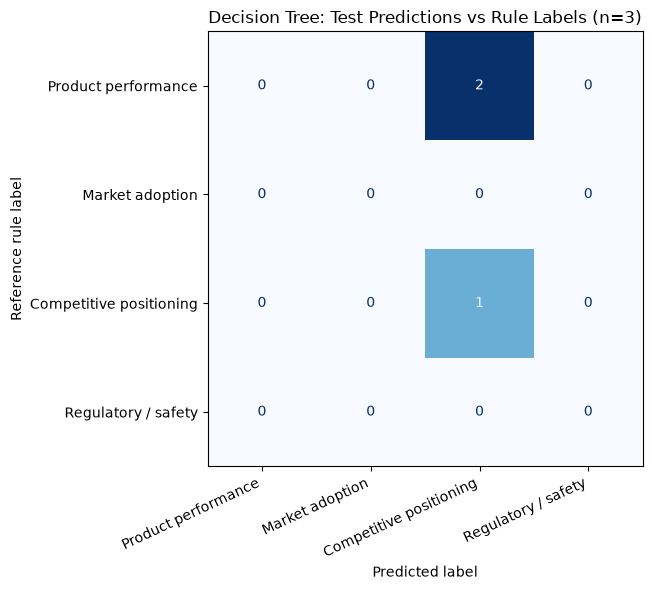

In [62]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict without refitting or changing model settings.
y_test = test_data["rule_label"]
y_pred = classifier_pipeline.predict(
    test_data["text_preprocessed"]
)

# Keep document-level predictions for inspection and export.
test_predictions = test_data[
    ["document_id", "title", "rule_label"]
].copy().reset_index(drop=True)

test_predictions["predicted_label"] = y_pred
test_predictions["agrees_with_rule"] = (
    test_predictions["rule_label"]
    == test_predictions["predicted_label"]
)

test_accuracy = accuracy_score(y_test, y_pred)

classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        labels=functional_labels,
        output_dict=True,
        zero_division=0
    )
).T

classification_report_df = classification_report_df.drop(
    index="accuracy",
    errors="ignore"
)
print(f"Test rule-label accuracy: {test_accuracy:.2%}")

print("\nPrecision, recall, F1, and test support:")
display(classification_report_df.round(3))

print("\nDocument-level test predictions:")
display(test_predictions)

# Rows are reference rule labels; columns are model predictions.
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=functional_labels
)

confusion_matrix_df = pd.DataFrame(
    cm,
    index=pd.Index(functional_labels, name="rule_label"),
    columns=pd.Index(functional_labels, name="predicted_label")
)

short_names = {
    "Product Performance Feedback": "Product performance",
    "Market Adoption Signal": "Market adoption",
    "Competitive Positioning": "Competitive positioning",
    "Regulatory or Safety Concern": "Regulatory / safety"
}

fig, ax = plt.subplots(figsize=(9, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[short_names[label] for label in functional_labels]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Decision Tree: Test Predictions vs Rule Labels (n=3)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Reference rule label")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout()

classification_figure_dir = classification_dir / "figures"
classification_figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    classification_figure_dir / "W06_DT_Confusion_Matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Decision Tree Feature Importance

Inspect the TF-IDF terms used by the fitted Decision Tree.
Importance measures each term's contribution to reducing training
Gini impurity, normalized across the tree.

Display only terms with positive importance. These values describe
this fitted model; they do not establish causal effects, semantic
validity, or reliable importance in a larger population.

Training vocabulary: 1768 terms
Terms used in tree splits: 3


,term,importance
0,shift,0.4
1,foster,0.3
2,intention,0.3


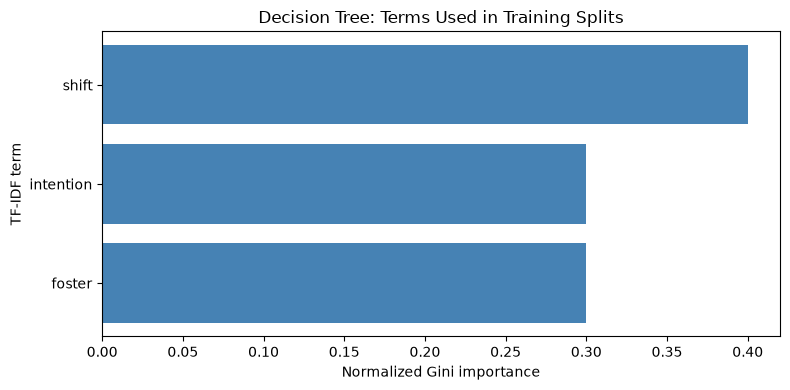

In [63]:
# Retain all terms for later export.
feature_importance_df = pd.DataFrame({
    "term": fitted_vectorizer.get_feature_names_out(),
    "importance": fitted_tree.feature_importances_
}).sort_values(
    ["importance", "term"],
    ascending=[False, True]
).reset_index(drop=True)

# Show only terms actually used in tree splits.
used_features = feature_importance_df.loc[
    feature_importance_df["importance"] > 0
].copy()

print(f"Training vocabulary: {len(feature_importance_df)} terms")
print(f"Terms used in tree splits: {len(used_features)}")

display(used_features)

if not used_features.empty:
    plot_features = used_features.head(10).sort_values(
        "importance",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.barh(
        plot_features["term"],
        plot_features["importance"],
        color="steelblue"
    )

    ax.set_xlabel("Normalized Gini importance")
    ax.set_ylabel("TF-IDF term")
    ax.set_title("Decision Tree: Terms Used in Training Splits")
    fig.tight_layout()

    fig.savefig(
        classification_figure_dir / "W06_DT_Feature_Importance.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("The fitted tree has no feature-based splits.")

### Classification Findings

The Decision Tree achieved 100% training accuracy and 33.33% test
accuracy against rule-generated labels. All three test documents
were predicted as Competitive Positioning.

Only three terms were used in the fitted tree: shift (0.40),
foster (0.30), and intention (0.30). Their weak semantic connection
to the functional categories suggests possible reliance on incidental
associations in the small training set.

Interpretation is limited by noisy rule labels, nine training documents,
three test documents, and the absence of two classes from the test set.
The model is an exploratory baseline and requires better labels and
broader evaluation before operational use.

### Export Classification Results

Export evaluation tables, document predictions, split membership,
class support, feature importance, and readable tree rules.

Reload the exported CSV files to verify that their contents are
preserved. Retain the manual annotations and frozen keyword rules
as reproducible project inputs.

In [64]:
from sklearn.tree import export_text

# Record which documents belong to each split.
split_membership = pd.concat(
    [
        train_data[
            ["document_id", "title", "rule_label"]
        ].assign(split="train"),
        test_data[
            ["document_id", "title", "rule_label"]
        ].assign(split="test")
    ],
    ignore_index=True
)

# Keep accuracy separate from the classification report.
report_export = (
    classification_report_df
    .drop(index="accuracy", errors="ignore")
    .rename_axis("label_or_average")
    .reset_index()
)

metrics_export = pd.DataFrame([
    {
        "metric": "Training rule-label accuracy",
        "value": training_accuracy
    },
    {
        "metric": "Test rule-label accuracy",
        "value": test_accuracy
    },
    {
        "metric": "Four-class macro F1 (zero_division=0)",
        "value": classification_report_df.loc[
            "macro avg", "f1-score"
        ]
    },
    {
        "metric": "Test-support-weighted F1",
        "value": classification_report_df.loc[
            "weighted avg", "f1-score"
        ]
    }
])

classification_exports = {
    "W06_DT_Classification_Report.csv": report_export,
    "W06_DT_Metrics.csv": metrics_export,
    "W06_DT_Test_Predictions.csv": test_predictions,
    "W06_DT_Confusion_Matrix.csv":
        confusion_matrix_df.reset_index(),
    "W06_DT_Feature_Importance.csv": feature_importance_df,
    "W06_DT_Split_Membership.csv": split_membership,
    "W06_DT_Class_Support.csv":
        class_support.rename_axis("rule_label").reset_index()
}

# Export and verify each table.
for filename, table in classification_exports.items():
    # CSV preserves column headers, but not the column-axis name.
    table = table.rename_axis(columns=None)

    output_path = classification_dir / filename

    table.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    reloaded = pd.read_csv(
        output_path,
        encoding="utf-8-sig",
        keep_default_na=False
    )

    pd.testing.assert_frame_equal(
        table.reset_index(drop=True),
        reloaded,
        check_dtype=False,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12
    )

    print(f"Export verified: {filename}")

# Export readable tree splits and their TF-IDF thresholds.
tree_rules = export_text(
    fitted_tree,
    feature_names=fitted_vectorizer.get_feature_names_out().tolist(),
    decimals=6
)

tree_rules_path = classification_dir / "W06_DT_Tree_Rules.txt"
tree_rules_path.write_text(tree_rules, encoding="utf-8")

assert tree_rules_path.read_text(encoding="utf-8") == tree_rules

print("Export verified: W06_DT_Tree_Rules.txt")
print("\nClassification result exports completed.")

Export verified: W06_DT_Classification_Report.csv
Export verified: W06_DT_Metrics.csv
Export verified: W06_DT_Test_Predictions.csv
Export verified: W06_DT_Confusion_Matrix.csv
Export verified: W06_DT_Feature_Importance.csv
Export verified: W06_DT_Split_Membership.csv
Export verified: W06_DT_Class_Support.csv
Export verified: W06_DT_Tree_Rules.txt

Classification result exports completed.


### Save Reproducibility Configuration

Record model parameters, split membership, package versions, and file
hashes. This configuration documents the inputs and settings used
to reproduce the classification baseline.

Manual annotations are retained as a completed input file and are
not regenerated during routine notebook execution.

In [65]:
import hashlib
import json
import platform
from importlib.metadata import version

def classification_file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

# Convert non-JSON parameter values to readable representations.
tfidf_parameters = fitted_vectorizer.get_params(deep=False).copy()
tfidf_parameters["tokenizer"] = "str.split"
tfidf_parameters["dtype"] = fitted_vectorizer.dtype.__name__
tfidf_parameters["ngram_range"] = list(
    tfidf_parameters["ngram_range"]
)

classification_input_paths = [
    Path("data") / "week6_inputs" / "W06_Analysis_Input.csv",
    classification_dir / "W06_Keyword_Rules_v1.json",
    classification_dir / "W06_Rule_Labels_v1.csv",
    classification_dir / "W06_Manual_Label_Audit.csv"
]

classification_output_paths = [
    classification_dir / filename
    for filename in classification_exports
] + [
    tree_rules_path,
    classification_dir / "W06_Rule_Manual_Comparison.csv",
    classification_dir / "W06_Rule_Audit_Summary.csv",
    classification_figure_dir / "W06_DT_Confusion_Matrix.png",
    classification_figure_dir / "W06_DT_Feature_Importance.png"
]

classification_config = {
    "method": "TF-IDF + Decision Tree",
    "text_column": "text_preprocessed",
    "target_column": "rule_label",
    "target_source": "Frozen keyword rules v1",
    "functional_labels": functional_labels,
    "excluded_rule_labels": ["Ambiguous", "Unmatched"],
    "manual_reference": {
        "annotation_process": "AI-assisted, human-reviewed",
        "documents_reviewed": len(manual_audit),
        "additional_label": "Other / Unclear",
        "scope": "Descriptive corpus audit, not independent gold standard"
    },
    "split": {
        "test_size_requested": 0.20,
        "random_state": 42,
        "shuffle": True,
        "stratify": None,
        "eligible_documents": len(model_data),
        "training_documents": len(train_data),
        "test_documents": len(test_data),
        "train_document_ids": train_data["document_id"].tolist(),
        "test_document_ids": test_data["document_id"].tolist()
    },
    "tfidf": {
        "fit_scope": "Training documents only",
        "parameters": tfidf_parameters,
        "vocabulary_size": len(
            fitted_vectorizer.get_feature_names_out()
        )
    },
    "decision_tree": fitted_tree.get_params(deep=False),
    "evaluation": {
        "reference": "Rule-generated labels",
        "zero_division": 0,
        "macro_average_labels": functional_labels,
        "classes_without_test_support": class_support.index[
            class_support["test_documents"].eq(0)
        ].tolist(),
        "test_based_parameter_tuning": False
    },
    "environment": {
        "python": platform.python_version(),
        "packages": {
            package: version(package)
            for package in [
                "numpy", "pandas", "scipy",
                "scikit-learn", "matplotlib"
            ]
        }
    },
    "input_sha256": {
        path.as_posix(): classification_file_hash(path)
        for path in classification_input_paths
    },
    "output_sha256": {
        path.as_posix(): classification_file_hash(path)
        for path in classification_output_paths
    }
}

classification_config_path = (
    classification_dir / "W06_Classification_Config.json"
)

classification_config_path.write_text(
    json.dumps(
        classification_config,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

reloaded_config = json.loads(
    classification_config_path.read_text(encoding="utf-8")
)

assert reloaded_config == classification_config

print("Classification configuration saved and verified.")

Classification configuration saved and verified.
